In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("hotel_bookings.csv")

df.shape

(119390, 32)

In [14]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [16]:
df["is_canceled"].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [ ]:
##The target variable is is_canceled: 0 means not cancelled and 1 means cancelled.

In [17]:
##2. Data cleaning
##We check missing values, duplicates, data types and outliers before training the models.

In [18]:
df.isnull().sum().sort_values(ascending=False).head(15)

company                      112593
agent                         16340
country                         488
children                          4
arrival_date_month                0
arrival_date_week_number          0
hotel                             0
is_canceled                       0
stays_in_weekend_nights           0
arrival_date_day_of_month         0
adults                            0
stays_in_week_nights              0
babies                            0
meal                              0
lead_time                         0
dtype: int64

In [19]:
df.isnull().mean().sort_values(ascending=False).head(15) * 100

company                      94.306893
agent                        13.686238
country                       0.408744
children                      0.003350
arrival_date_month            0.000000
arrival_date_week_number      0.000000
hotel                         0.000000
is_canceled                   0.000000
stays_in_weekend_nights       0.000000
arrival_date_day_of_month     0.000000
adults                        0.000000
stays_in_week_nights          0.000000
babies                        0.000000
meal                          0.000000
lead_time                     0.000000
dtype: float64

In [ ]:
##Explanation: The first code shows missing-value counts, while the second shows the percentage of missing values in each column.

In [20]:
df.duplicated().sum()

np.int64(31994)

In [21]:
df = df.drop_duplicates()

In [21]:
##Why? Exact duplicate rows can cause repeated observations to receive too much influence during training.

In [22]:
##Remove data leakage##
df = df.drop(
    columns=[
        "reservation_status",
        "reservation_status_date",
        "company"
    ],
    errors="ignore"
)

In [23]:
##- reservation_status can directly reveal whether a booking was cancelled.
##- reservation_status_date can reveal information associated with the final booking outcome.
###- company has many missing values and may not provide enough useful information for this version of the model.
##Removing the first two is particularly important because the goal is to predict cancellation before it happens.

In [23]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [24]:
df["is_canceled"] = df["is_canceled"].astype(int)

In [ ]:
##We will let the preprocessing pipeline handle the numerical and categorical feature types. 
# We should not convert every integer column to a category because some integers, 
# such as lead_time, represent meaningful numerical quantities.

In [25]:
df[["lead_time", "adr", "adults", "children", "babies"]].describe()

,lead_time,adr,adults,children,babies
count,87396.000000,87396.000000,87396.000000,87392.000000,87396.000000
mean,79.891368,106.337246,1.875795,0.138640,0.010824
std,86.052325,55.013953,0.626500,0.455881,0.113597
min,0.000000,-6.380000,0.000000,0.000000,0.000000
25%,11.000000,72.000000,2.000000,0.000000,0.000000
50%,49.000000,98.100000,2.000000,0.000000,0.000000
75%,125.000000,134.000000,2.000000,0.000000,0.000000
max,737.000000,5400.000000,55.000000,10.000000,10.000000


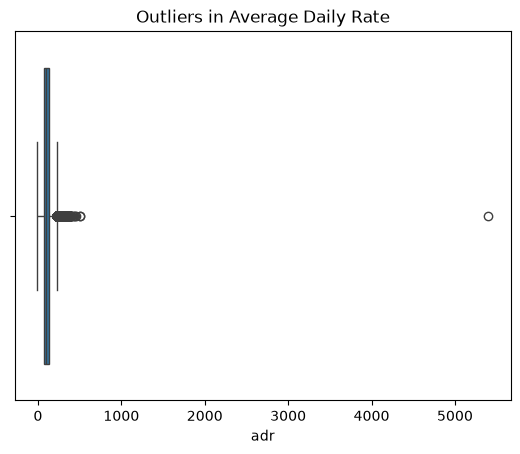

In [26]:
sns.boxplot(x=df["adr"])
plt.title("Outliers in Average Daily Rate")
plt.show()

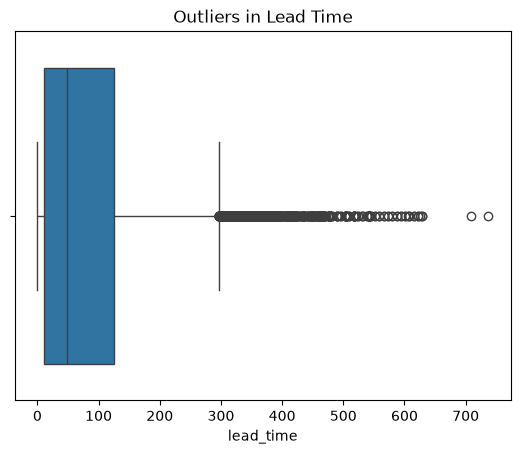

In [27]:
sns.boxplot(x=df["lead_time"])
plt.title("Outliers in Lead Time")
plt.show()

In [ ]:
##Explanation: Boxplots identify unusually high or low values. 
# These values are not automatically errors. For example, a long lead time or high daily rate may be a genuine booking. 
# We should investigate impossible values rather than remove all statistical outliers automatically.
#The preprocessing pipeline will impute missing feature values during training.

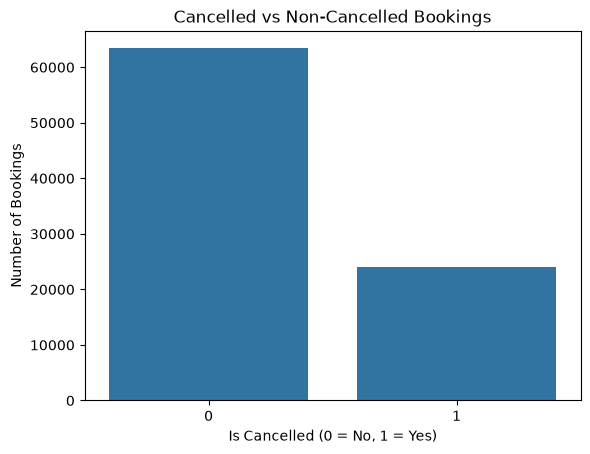

In [28]:
##Data visualisation#
#We will create five charts. Each chart should help explain a business pattern, 
# not just make the notebook look attractive.
#Target variable distribution
sns.countplot(data=df, x="is_canceled")
plt.title("Cancelled vs Non-Cancelled Bookings")
plt.xlabel("Is Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")
plt.show()

In [ ]:
#This chart shows the proportion of cancelled and non-cancelled bookings. 
# If the classes are imbalanced, accuracy alone may be misleading.

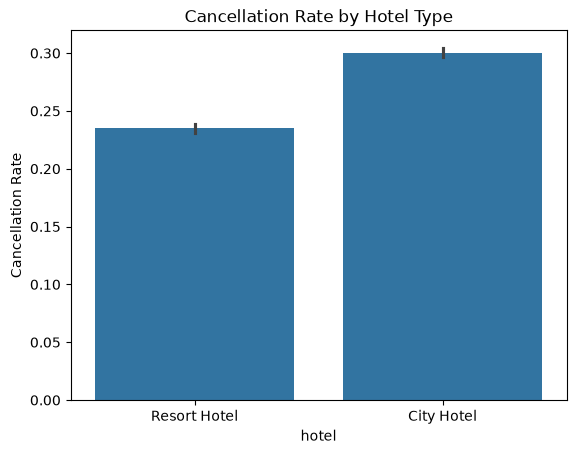

In [29]:
##Cancellation by hotel type#
sns.barplot(data=df, x="hotel", y="is_canceled")
plt.title("Cancellation Rate by Hotel Type")
plt.ylabel("Cancellation Rate")
plt.show()

In [ ]:
##The cancellation rate may differ between City Hotels and Resort Hotels, 
# helping identify which hotel type needs closer attention.

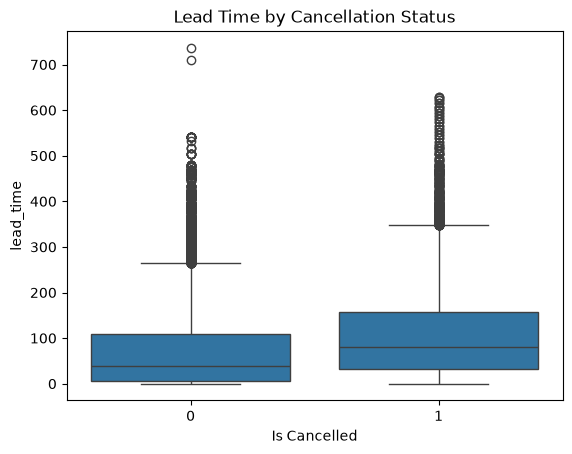

In [30]:
sns.boxplot(data=df, x="is_canceled", y="lead_time")
plt.title("Lead Time by Cancellation Status")
plt.xlabel("Is Cancelled")
plt.show()

In [ ]:
##This compares how far in advance customers book, depending on whether they later cancel.

In [ ]:
##Deposit type and cancellation#

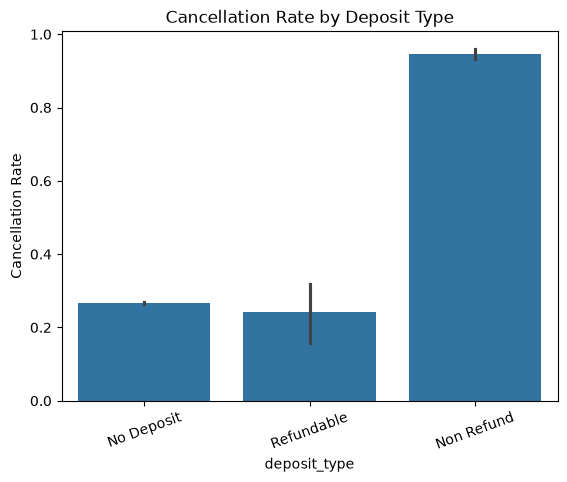

In [31]:
sns.barplot(data=df, x="deposit_type", y="is_canceled")
plt.title("Cancellation Rate by Deposit Type")
plt.ylabel("Cancellation Rate")
plt.xticks(rotation=20)
plt.show()

In [32]:
##Differences in cancellation rates across deposit policies may help the hotel evaluate its booking and deposit strategy. 
# This relationship does not by itself prove causation.

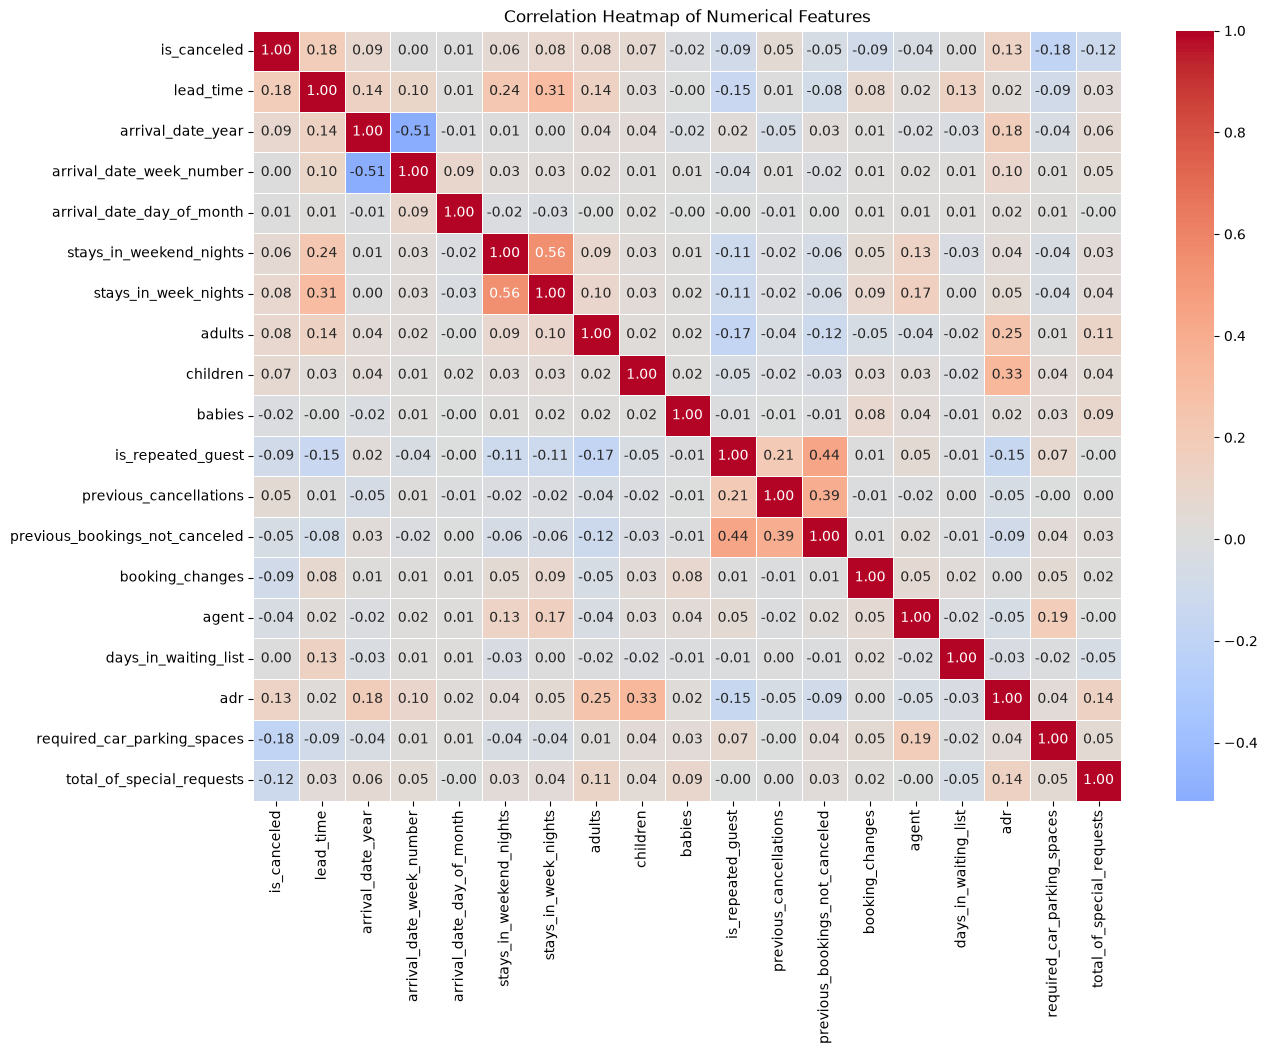

In [33]:
##Correlation heatmap
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation,
    annot=True,        # ← add this
    fmt=".2f",         # optional: round to 2 decimal places
    cmap="coolwarm",
    center=0,
    linewidths=0.5     # optional: add gridlines between cells
)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [ ]:
##The heatmap identifies numerical features with positive or negative linear relationships.
#  Correlation does not prove causation, and a weak correlation does not necessarily mean a feature is unimportant to a nonlinear model.
#We deliberately excluded the leakage columns before calculating the heatmap.

In [ ]:
##Data preprocessing#
##The most important rule is to split the data before fitting imputers, encoders, scalers or PCA.

In [34]:
##Separate features and target#
X = df.drop("is_canceled", axis=1)
y = df["is_canceled"]

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
##We use 80% for training and 20% for testing. stratify=y keeps the class proportions approximately consistent.

In [36]:
##Create numerical and categorical pipelines
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

In [ ]:
##Explanation
##- Imputation: fills missing numerical values with the median and categorical values with the most frequent value.
##- Encoding: converts categorical columns into numerical indicators using one-hot encoding.
##- Scaling: puts numerical features on comparable scales, which is particularly useful for Logistic Regression.
##- Pipeline: learns preprocessing parameters from the training data when .fit() is called.

In [ ]:
#We do not use pd.get_dummies() on the full dataset before splitting, because fitting transformations 
#inside the pipeline gives us a more reliable training and testing process.

In [ ]:
##Problem type
##his is a supervised binary classification problem.
##- Supervised learning: we have historical bookings with known outcomes.
##- Binary classification: the target has two classes, 0 and 1.
##- Prediction: the model estimates whether a booking will be cancelled.

##The model can output a cancellation probability and convert it into a class prediction.

In [ ]:
##For this hotel business problem, F1-score and recall are especially important.
##- Recall: Of all bookings that were actually cancelled, how many did the model identify?
##- Precision: Of the bookings predicted to be cancelled, how many were actually cancelled?
##- F1-score: Balances precision and recall.
##- Accuracy: Percentage of all predictions that were correct.
##- ROC-AUC: Measures how well the model ranks cancelled bookings above non-cancelled bookings across different thresholds.
##- Confusion matrix: Shows true positives, true negatives, false positives and false negatives.

In [ ]:
##If missing a cancellation is particularly costly, recall may deserve more emphasis. If unnecessary actions on bookings predicted to cancel are costly, precision matters too.

In [ ]:
##Model comparison
##We will train three algorithms from your project: Logistic Regression, Decision Tree and Random Forest. 
# All three use the same train/test split and preprocessing approach.

In [37]:
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pca_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("pca", PCA(n_components=100, svd_solver="arpack")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_pca_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['hotel','lead_time','arrival_date_year',...,'adr', 'required_car_parking_spaces','total_of_special_requests']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dr

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

In [ ]:
##The models use class_weight="balanced" to account for the class distribution. 
# The Decision Tree and Random Forest have depth and leaf-size limits to help control overfitting.

In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    train_predictions = pipeline.predict(X_train)
    test_predictions = pipeline.predict(X_test)

    train_probabilities = pipeline.predict_proba(X_train)[:, 1]
    test_probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test, test_predictions
        ),
        "Train F1": f1_score(
            y_train, train_predictions
        ),
        "Test F1": f1_score(
            y_test, test_predictions
        ),
        "Test Precision": precision_score(
            y_test, test_predictions, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, test_predictions, zero_division=0
        ),
        "Test ROC-AUC": roc_auc_score(
            y_test, test_probabilities
        )
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Test F1",
    ascending=False
)

results_df.round(3)

,Model,Train Accuracy,Test Accuracy,Train F1,Test F1,Test Precision,Test Recall,Test ROC-AUC
2,Random Forest,0.820,0.793,0.736,0.695,0.585,0.857,0.898
1,Decision Tree,0.832,0.799,0.743,0.694,0.596,0.830,0.879
0,Logistic Regression,0.755,0.750,0.640,0.636,0.531,0.794,0.845


In [ ]:
##Result
##High train F1, much lower test F1	Possible overfitting
##Similar train and test F1	Better generalisation, assuming both scores are good
##High recall, low precision	Finds more cancellations but produces more false alarms
##High precision, low recall	Predictions are often correct, but many cancellations are missed
##High ROC-AUC	Better separation of cancelled and non-cancelled bookings across thresholds

Best model: Random Forest
              precision    recall  f1-score   support

           0       0.93      0.77      0.84     12675
           1       0.58      0.86      0.69      4805

    accuracy                           0.79     17480
   macro avg       0.76      0.81      0.77     17480
weighted avg       0.84      0.79      0.80     17480



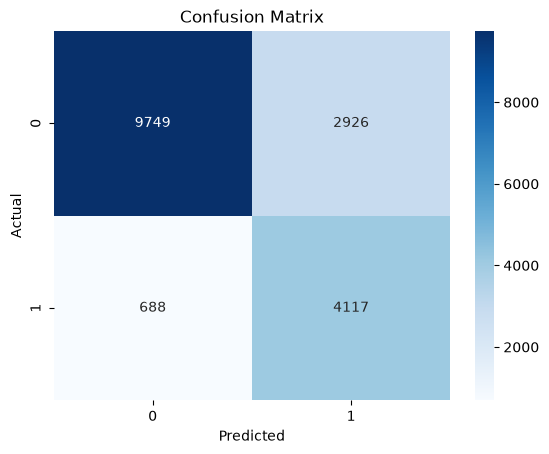

In [41]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best model:", best_model_name)

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

sns.heatmap(
    confusion_matrix(y_test, best_predictions),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
##I used the confusion matrix on the test data to evaluate my Random Forest model on unseen bookings. It helped me identify correct predictions, 
##false alarms and cancellations that the model missed.”
##The confusion matrix shows correct predictions and mistakes, including canceled bookings predicted as non-canceled and non-canceled bookings predicted as canceled.

In [ ]:
##Best algorithm and why
#We need to consider four things when selecting the final model:
#1. Test performance: Is its test F1-score competitive?
#2. Generalisation: Is the gap between training and test performance reasonably small?
#3. Interpretability: Can we explain the factors behind predictions?
#4. Speed: Can we train and use the model efficiently?

In [43]:
results_df["F1 Gap"] = (
    results_df["Train F1"] - results_df["Test F1"]
).abs()

results_df[
    ["Model", "Train F1", "Test F1", "F1 Gap"]
].round(3)

,Model,Train F1,Test F1,F1 Gap
0,Random Forest,0.736,0.695,0.041
1,Decision Tree,0.743,0.694,0.049
2,Logistic Regression,0.640,0.636,0.004


In [ ]:
##A large gap can indicate overfitting. A small gap is useful, 
# but it does not guarantee that the model is accurate enough for the business.

In [ ]:
##Update the encoder for PCA
# ##PCA requires dense input. For this version, set one-hot encoding to return a dense array and ##
# force the column transformer to return dense output.

In [46]:
from sklearn.decomposition import PCA

categorical_pipeline_pca = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor_pca = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline_pca, categorical_columns)
    ],
    sparse_threshold=0
)

In [ ]:
##Train Random Forest with PCA
##We will use 100 components, provided the preprocessed training data has at least 100 features.

In [47]:
rf_pca_pipeline = Pipeline([
    ("preprocessor", preprocessor_pca),
    ("pca", PCA(
        n_components=100,
        svd_solver="randomized",
        random_state=42
    )),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pca_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['hotel','lead_time','arrival_date_year',...,'adr', 'required_car_parking_spaces','total_of_special_requests']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to alw

In [ ]:
##Compare Random Forest with and without PCA

In [48]:
rf_without_pca = trained_models["Random Forest"]

rf_predictions = rf_without_pca.predict(X_test)
rf_pca_predictions = rf_pca_pipeline.predict(X_test)

pca_comparison = pd.DataFrame([
    {
        "Method": "Random Forest without PCA",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Precision": precision_score(y_test, rf_predictions),
        "Recall": recall_score(y_test, rf_predictions),
        "F1 Score": f1_score(y_test, rf_predictions),
        "ROC-AUC": roc_auc_score(
            y_test,
            rf_without_pca.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Method": "Random Forest with PCA",
        "Accuracy": accuracy_score(y_test, rf_pca_predictions),
        "Precision": precision_score(y_test, rf_pca_predictions),
        "Recall": recall_score(y_test, rf_pca_predictions),
        "F1 Score": f1_score(y_test, rf_pca_predictions),
        "ROC-AUC": roc_auc_score(
            y_test,
            rf_pca_pipeline.predict_proba(X_test)[:, 1]
        )
    }
])

pca_comparison.round(3)

,Method,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest without PCA,0.793,0.585,0.857,0.695,0.898
1,Random Forest with PCA,0.825,0.755,0.538,0.628,0.878


In [ ]:
##Check how much variance PCA retains
#This tells you the proportion of variance retained by the 100 components.

In [49]:
pca_variance = rf_pca_pipeline.named_steps["pca"].explained_variance_ratio_.sum()

pca_variance

np.float64(0.9989469757882375)

In [56]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

rf_pca_pipeline.fit(X_train, y_train)

pca_predictions = rf_pca_pipeline.predict(X_test)

pca_probabilities = rf_pca_pipeline.predict_proba(X_test)[:, 1]

pca_results = {
    "Model": "Random Forest PCA",
    "Test F1": f1_score(y_test, pca_predictions),
    "Test Precision": precision_score(y_test, pca_predictions),
    "Test Recall": recall_score(y_test, pca_predictions),
    "Test ROC-AUC": roc_auc_score(y_test, pca_probabilities)
}

pca_results

{'Model': 'Random Forest PCA',
 'Test F1': 0.6281614785992218,
 'Test Precision': 0.7554840596665692,
 'Test Recall': 0.5375650364203954,
 'Test ROC-AUC': 0.8778366716130266}

In [58]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_validation_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    rf_validation_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True
)

print("Mean Validation Accuracy:", cv_results["test_accuracy"].mean())
print("Mean Validation Precision:", cv_results["test_precision"].mean())
print("Mean Validation Recall:", cv_results["test_recall"].mean())
print("Mean Validation F1:", cv_results["test_f1"].mean())
print("Mean Validation ROC-AUC:", cv_results["test_roc_auc"].mean())
print("Mean Training F1:", cv_results["train_f1"].mean())

Mean Validation Accuracy: 0.7944104006401366
Mean Validation Precision: 0.5858773855237283
Mean Validation Recall: 0.8601977107180021
Mean Validation F1: 0.6969956540753643
Mean Validation ROC-AUC: 0.9005614896337922
Mean Training F1: 0.7406744494702957


In [ ]:
##Evaluate the final model on test data
##After validation, train the model on the complete training set and evaluate it on the untouched test set.

              precision    recall  f1-score   support

           0       0.93      0.77      0.84     12675
           1       0.58      0.86      0.69      4805

    accuracy                           0.79     17480
   macro avg       0.76      0.81      0.77     17480
weighted avg       0.84      0.79      0.80     17480



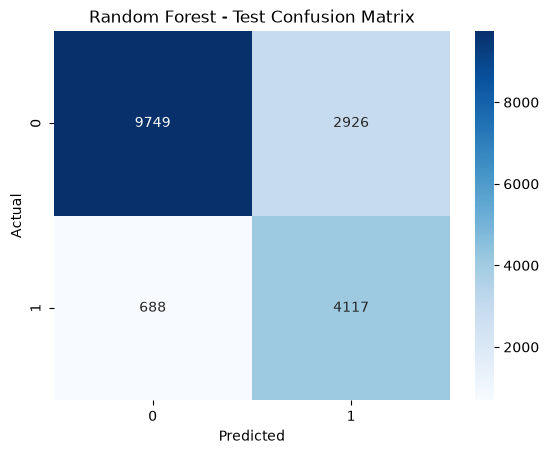

In [59]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

rf_validation_pipeline.fit(X_train, y_train)

y_pred = rf_validation_pipeline.predict(X_test)

print(classification_report(y_test, y_pred))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest - Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
#Tune Random Forest
##This tests different combinations of parameters and selects the combination with the best cross-validation F1-score. It can take some time to run.

In [60]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [2, 3, 5]
}

grid_search = GridSearchCV(
    rf_validation_pipeline,
    param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best validation F1:", grid_search.best_score_)

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 300}
Best validation F1: 0.7284107981966371


In [ ]:
##Evaluate the tuned model on test data

Test Accuracy: 0.8314645308924485
Test Precision: 0.6534588079907545
Test Recall: 0.8237252861602498
Test F1: 0.7287792303443197
Test ROC-AUC: 0.9107235682751572


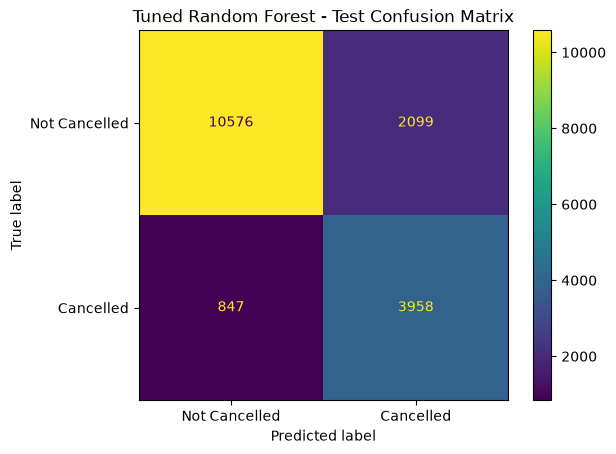

In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test Precision:", precision_score(y_test, y_pred))
print("Test Recall:", recall_score(y_test, y_pred))
print("Test F1:", f1_score(y_test, y_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Cancelled", "Cancelled"]
)

plt.title("Tuned Random Forest - Test Confusion Matrix")
plt.show()